# II. How to: CompressSkipperProcess
# Averaging an skipper CCD image

# Introduction

`CompressSkipperProcess` is the class used to compress an skipper image. This class allow to use any statistical function from [numpy](https://numpy.org/) to reduce the single skip images into a unique one by computing the arithmetic function along the 3rd axis of `RawData.image` (see [how to I](./I_howto_RawData.html)). As a reminder, the CCD image is loaded as a data member of an instance of the `RawData` class as an array of dimension 3:

```python
    (Nrows, Ncols, Nskips)
```

Where $Nskips$ is the number of non-destructive measurement the charge have been done.

This process will create a new data member of the raw data object under the name `image_<func>_compressed` where `<func>` is the function name used to reduce the set of non-destructive measurement per pixel into a single one. This new data memeber is an array of dimension 2:

```python
    (Nrows, Ncols)
```



## Configuration parameters for `CompressSkipImage`

#### `image` config param

Is the image to be compressed. By default is the raw data.

#### `func_to_compress` config param

List of arithmetic functions to compress the non-destructive measurements. One image for each function will be created and added as a data member of the `RawData` instance. The default funciton is [mean](https://numpy.org/doc/stable/reference/generated/numpy.mean.html). 

#### `id_skip_start` config param

To create the compressed image, it is not mandatory to use the full set of non-destructive measurements. This parameters should point to the first measurement to take into account. Note that the first value is *0*. 

#### `id_skip_end` config param

To create the compressed image, it is not mandatory to use the full set of non-destructive measurements. This parameters should point to the last measurement to take into account. Negative values means *the last one*. 



# Index 

In this howto there are two sections:

  * Section A: How to from a Python Interpreter
  * Section B: How to from bash
  
In both cases, we will do the same (fit the dark current), but using two different approaches. The first option allows yo to get to know and go deeper into the different sub-modules of `pysimdamicm` as a black box through the `panaSKImg` script.


## A. How to from a Python Interpreter

### Following prebious howto 

1. Load all modules needed for this **howto**
2. Defie which data to be used
3. Load Configuration file (see [how to I](./howto_Config.html))
4. Create a RawData object (see [how to I](./I_howto_RawData.html))
5. Compress image (this how to)


### 1. Load `pysimdamicm` and some other useful packages

In [1]:
%matplotlib inline

# loading damicm module
import pysimdamicm as ccd

# loading other packages
import numpy as np
from matplotlib import pyplot as plt
import ROOT

Welcome to JupyROOT 6.14/06


### 2. Define where your data is 

In [2]:
# variable pointing where my#### data is
path_to_raw_data = "/data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img/"

# pattern file name
img_pattern_file_name = "Image_Am241_Source_55_{}.fits"
# absolute path to the file name
file_name = "{}/{}".format(path_to_raw_data,img_pattern_file_name)

print("\nMy images follows the patter file name:\n {}\n".format(file_name.format("*")))


My images follows the patter file name:
 /data/workdir/compton/data/calidaq_backup/DataTaking/Am241/skip_2000_img//Image_Am241_Source_55_*.fits



### 3. Load Configuration file

For this example I will use the default configuration file `panaSKImg_configuration.json` that can be found at `pysimdamicm.json`. 

To load this configuration file you can use the class `Config` provided by `pysimdamicm.utils.config`. This class reads and interpret JSON files to configure simulations and data. 


In [3]:
# path where our JSON file is
cfg_file = "{}/json/panaSKImg_configuration.json".format(ccd.__path__[0])

# False to interpret the JSON file as a configuration for data instead of simulations (default one) 
cfg = ccd.utils.config.Config(cfg_file, simulations=False)

In [4]:
print(" 'cfg' contains a dictionary {} with two main sections: ".format(type(cfg.configuration)))
for k in cfg.configuration.keys(): print("\t * ", k)
    
print("\n Where each section contains a set of sections: ")
_ =  [[print("\t {}: {}".format(k,sk)) for sk in cfg.configuration[k]] for k in sorted(cfg.configuration.keys())]

 'cfg' contains a dictionary <class 'dict'> with two main sections: 
	 *  input
	 *  process

 Where each section contains a set of sections: 
	 input: image
	 input: convention
	 input: scp
	 process: ChargeLossPlot
	 process: RNvsNskipsPlot
	 process: FitCalibrationConstant
	 process: PedestalSubtractionProcess
	 process: SignalPatternRecognition
	 process: ClusterFinder
	 process: MaskImageProcess
	 process: CompressSkipperProcess
	 process: sequence
	 process: FFTNoisePlot
	 process: FitDarkCurrentProcess


For now we will just focus on section **input** that corresponds to our input data, i.e. our image. Relevant for this exercise are the sections:

* conventions: to inform the name of some keywords that should be found in the header of the input file
* image: to inform about overscan and prescan regions, skip range, coorections to apply data before execute any process ... 

In [5]:
print(ccd.utils.config.json.dumps(cfg.configuration['input'], indent=4, sort_keys=True))

{
    "convention": {
        "Ncols": "NAXIS1",
        "Npbin": "NPBIN",
        "Nrows": "NAXIS2",
        "Nsbin": "NSBIN",
        "Nskips": "NDCMS",
        "ampl": "AMPL",
        "exposure_time": "MEXP",
        "read_time": "MREAD"
    },
    "image": {
        "active_region_cols": null,
        "active_region_rows": null,
        "axis_to_compress": 1,
        "correct_leach_bug": true,
        "correct_polarity": false,
        "extensions": 0,
        "id_col_end": -1,
        "id_col_start": 0,
        "id_row_end": -1,
        "id_row_start": 0,
        "id_skip_end": -1,
        "id_skip_start": 3,
        "n_cols_overscan": 15,
        "n_cols_prescan": 2,
        "n_rows_overscan": 0,
        "n_rows_prescan": 0,
        "skip_image": true
    },
    "scp": {}
}


From the **image** section:
* the image should be corrected by the 'leach_bug' but not from 'polarity'
* axis to compress corresponds the direccion of the serial register, in this case: cols (1)
* overscan col region: 15 last columns
* prescan col region: 2 first columns
* no overscan and prescan on rows
* the rest of the image, will be interpreted as the sensor or active region
* skip region: starting with mesaure 3 up to the last (negative value implies last dimension, -1)


### 4. Create a RawData object

The class `BuilderRawData` provided by `pysimdamicm.io.rawdata` is used to create an object with our data from the input file (in this example, as a fits file object). 

This class can use the default configuration to properly set our data object as an instance of `RawData`.


In [6]:
# unset verbose for the fits file header
ccd.io.rawdata.__verbose__ = False
rdata = ccd.io.rawdata.BuilderRawData(file_name.format('skip_1'), cfg.configuration['input'])

Correction INFO. Correcting data for Leach bug:
 	 the first two column moved to the end,
 	 move one-row down (only the two last columns).



#### An extra step is needed to read all regions of an image: overscan, prescan and sensor regions

Internally what this function does is the creation of a boolean array for each region. This boolean array with the same size than the full image, should be used against the object `rdata.image_mean_compressed` to select only regions we are insterested in by using `numpy.ma.array`. The object `rdata.image_mean_compressed` is the averaged skip image (see next steps).

In [7]:
rdata.prepare_data()

RawData INFO.
 *********************************************************************** 
 ********* Define mask for sensor and over/pre-scan regions 'Image_Am241_Source_55_skip_1.fits' ********* 
 *********************************************************************** 

 * Active region: 
		rows=0:60
		cols=2:260

 * Overscan  in cols: 
		rows=0:60
		cols=260:275

 * Prescan  in cols: 
		rows=0:60
		cols=0:2

 * NO Overscan  in rows

 * NO Prescan in rows
 ***********************************************************************. 



#### Our data image 

The attribute `image` of `rdata` contains our data image. It is an array of 3 dimensions if the input file corresponds to an skipper image, and a 2D is is the already averaged image.

The dimensions are for:
* number of rows
* number of cols
* number of skips

In [8]:
rdata.image.shape

(60, 275, 2000)

This image has 60 rows, 275 columns and each pixels has been measured 2000 times.

### 5. Compress image (this how to)

$\color{red}{\text{CompressSkipperProcess}}$ is a process used to compute the averaged skipper image

To compress the image we will use the class `CompressSkipperProcess` provided by `pysimdamicm.process.skiper_analysis`.

In [9]:
comp = ccd.processes.skipper_analysis.CompressSkipperProcess()

### How can we configure this process?

The user can change the following configuration parameters:

In [10]:
comp.info()

<CompressSkipsProcess> with sequence id 10.
 List of public data members: 
	 * __sequence_id__ = 10 
	 * __verbose__ = False 
	 * func_to_compress = ['mean', 'std'] 
	 * id_col_end = nan 
	 * id_col_start = nan 
	 * id_row_end = nan 
	 * id_row_start = nan 
	 * id_skip_end = nan 
	 * id_skip_start = nan 
	 * image = raw 
	 * save_image = False 
	 * save_plots = False 


* The parameters `id_XXX_start` and `id_XXX_col` can be used to limit a region of the image where the process will be executed. The user can limit the columns, rows or skips. These parameters are from the abstract classs `abps`, any process will have them, but not always have sense to delimit. Be careful on using it! If no region is defined, the one by default will be selected. If these parameters have been defined through the configuration JSON filethis parameters on the JSON file when loading data, these will be used.

* `func_to_compress` is a list of statistical functions (that must exist on `numpy`) to create the image. A compressed image for each function will be created and added as a new attribute on the `RawData` with the name: `image_FUNC_compressed` where `FUNC` is the used function name. 

* `save_img` to save the compressed image as a fits file
* `save_plots` to save the debug plots

Set `__verbose__` to see online the debug plots.


### Example 1: Compress the image without using the first 10 measurements

Process <CompressSkipsProcess> INFO. Compressing raw image data using the following statistics: ['mean']
     - used skip range 10:2000
     - image (60, 275, 1990) have been reduced to 60x275



/home/ncastello/.local/lib/python3.5/site-packages/matplotlib/figure.py:98: MatplotlibDeprecationWarning: 
Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  "Adding an axes using the same arguments as a previous axes "


Total pixel charge:  80913010.51758793


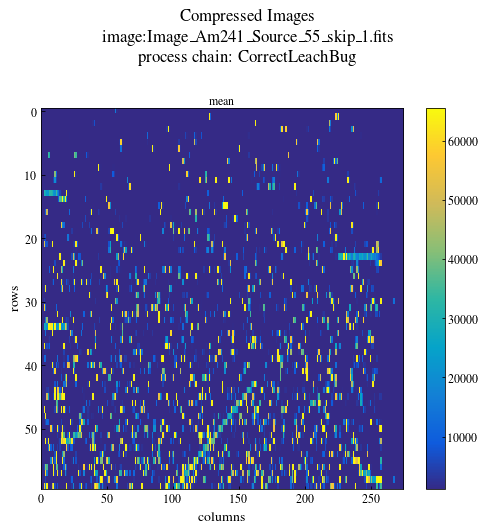

In [11]:
%matplotlib inline
comp.func_to_compress = ['mean']
comp.__verbose__ = True
comp.id_skip_start = 10
comp.execute_process(rdata)
print("Total pixel charge: ", rdata.image_mean_compressed.sum())

### Example 2: Compress the image without using the first 2 measurements:

Process <CompressSkipsProcess> INFO. Compressing raw image data using the following statistics: ['mean']
     - used skip range 3:2000
     - image (60, 275, 1997) have been reduced to 60x275

Total pixel charge:  80877574.28843266


/home/ncastello/.local/lib/python3.5/site-packages/matplotlib/figure.py:98: MatplotlibDeprecationWarning: 
Adding an axes using the same arguments as a previous axes currently reuses the earlier instance.  In a future version, a new instance will always be created and returned.  Meanwhile, this warning can be suppressed, and the future behavior ensured, by passing a unique label to each axes instance.
  "Adding an axes using the same arguments as a previous axes "


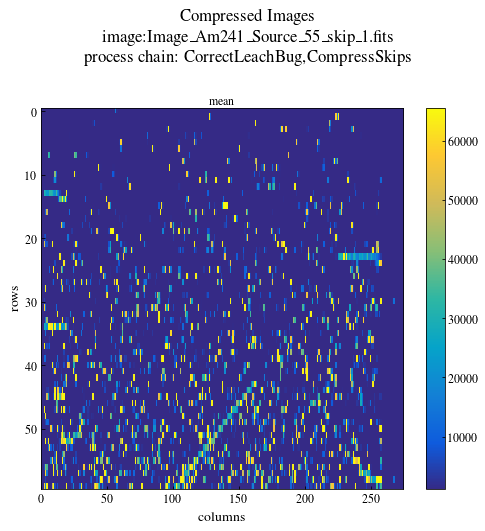

In [12]:
comp.__verbose__ = True
comp.id_skip_start = 3
comp.execute_process(rdata)
print("Total pixel charge: ", rdata.image_mean_compressed.sum())

### Example 3: Compress the image using several functions

Process <CompressSkipsProcess> INFO. Compressing raw image data using the following statistics: ['mean', 'median', 'std']
     - used skip range 3:2000
     - image (60, 275, 1997) have been reduced to 60x275



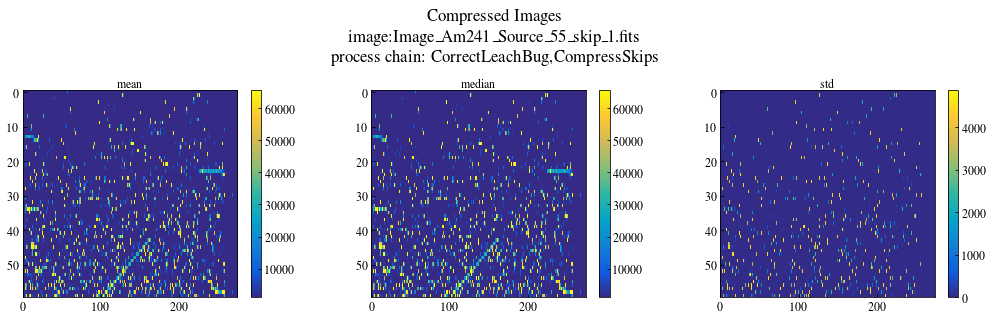

In [13]:
comp.__verbose__ = True
comp.func_to_compress = ['mean','median','std']

comp.id_skip_start = 3
comp.execute_process(rdata)


## B. How to from bash: panaSKImg

The main script for analysis is `panaSKImg` also provided by `pysimdamicm`. It is a python3 script to apply a chain of processes over a real data CCD image. Find more information [here](https://ncastell.web.cern.ch/ncastell/pysimdamicm/howtouse_analysis.html).

To $\color{green}{\text{compress}}$ a set of skipper images we can also use `panaSKImg`. We will only need 
* a configuration JSON file and 
* the input image files

Here is an example of how to run the same as in **Sect. A** (*How to from a Python Interpreter*), but with `panaSKImg`:

```console
    panaSKImg --json <config_file.json> "image_files*fits" --display --verbose -o .
```

Use `display` and `verbose` only to display all plots created along the process.

### How to set the parameters of each process?
Two possible ways:

* Using the configuration file
* Or using command lines

It is possible to use both the json file and command lines. $\color{green}{\text{The command lines have preference over those of the json file.}}$

#### by using the JSON file

This has to be done in the configuration file. [Here](./howto_Config.html) you can find information about the full JSON file.
```json
      "CompressSkipperProcess":
      {
         "func_to_compress":["mean"],
         "id_skip_start":3,
         "id_skip_end":-1
      },
```

All these parameters have been explained along this howto.



#### by command line

Almost all parameters has a command line to be pass as an argument of `panaSKImg`. Run

```console
    panaSKImg --help
```

for help on the command lines. Here the output of the help related with `CompressSkipperProcess`

```console
  --skip-start ID_SKIP_START
                        First skip to start with (for all processes, if a
                        process use an specific starting point include
                        id_skip_start in its scope in the json file)
  --skip-end ID_SKIP_END
                        First skip to start with (for all processes, if a
                        process use an specific starting point include
                        id_skip_start in its scope in the json file). Note
                        that -1 means last value

*** For Process CompressSkipperProcess ************************** :
  --func-to-compress FUNC_TO_COMPRESS [FUNC_TO_COMPRESS ...]
                        CompressSkipperProcess. List of functions to reduce
                        the single skipper images into a single one (functions
                        must exist in the numpy package)

```


#### `sequence` is mandatory

Remember that the parameter `sequence` of the `process` section of the JSON file must be informed. You can do that using the command line **-s** as follows

```console
    panaSKImg --json <config_file.json> "image_file*fits" --display --verbose -o . -s CompressSkipperProcess
```


To list all possible process you can just run

```console
    panaSKImg --list-process help
```

### Summary

To compress a set of images located at **/data/compton/run045** that follows the file name patter **Image*Source*fits** and store its compressed image in the current working directory just do


```console
    panaSKImg --json <config_file.json> -s CompressSkipperProcess "/data/compton/run045/Image*Source*fits" -o .
```

where `<config_file.json>` points to the configuration json file.